# Growth and division

A cell grows by gaining elements and divides by handing some of them to a new cell. The environment provides
three operations and leaves the decision of *when* to the caller:

| Operation | Effect |
|---|---|
| `grow_cell(cell)` | adds one element, one equilibrium distance from a random member, where there is the most room |
| `divide_cell(cell, normal, daughter_fraction)` | a plane perpendicular to `normal` splits the cell; the fraction of elements furthest along `normal` becomes a new cell |
| `longest_axis(cell)` | the direction the cell is most stretched along |

Element parameters stay fixed, so a cell with twice the elements has twice the volume. No element moves at
the moment of division: elements across the plane merely switch from the intra- to the weaker inter-cellular
potential, and the daughters separate by relaxation.

`daughter_fraction = 0.5` is a symmetric division. Any other value is an **asymmetric division**: 0.3 gives
daughters holding 30% and 70% of the elements.

The data below comes from the `growth_division` example. One cell of 32 elements goes through three
generations; in each, every cell doubles its element count and then divides across its longest axis.

```bash
E=build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.growth_division
D=mechanics/micromechanics/docs/notebooks/data
for fraction in 0.5 0.3; do $E $fraction 3 32 > $D/growth_division_$fraction.csv; done
```

Default potential ($\rho = 2$), no noise.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load(fraction):
    table = np.genfromtxt(Path("data") / f"growth_division_{fraction}.csv", delimiter=",", names=True,
                          skip_header=1, dtype=None, encoding="utf-8")
    snapshots = []
    for phase, generation in dict.fromkeys(zip(table["phase"], table["generation"])):
        rows = table[(table["phase"] == phase) & (table["generation"] == generation)]
        snapshots.append(dict(phase=str(phase), generation=int(generation), time=float(rows["time"][0]),
                              cell=rows["cell"].astype(int),
                              position=np.stack([rows[a] for a in "xyz"], axis=-1)))
    return snapshots


runs = {fraction: load(fraction) for fraction in ("0.5", "0.3")}
for fraction, snapshots in runs.items():
    print(f"fraction {fraction}:", ", ".join(f"{s['phase']} {s['generation']}: {np.unique(s['cell']).size} cells / {s['cell'].size} elements" for s in snapshots))

fraction 0.5: start 0: 1 cells / 32 elements, grown 1: 1 cells / 64 elements, divided 1: 2 cells / 64 elements, grown 2: 2 cells / 128 elements, divided 2: 4 cells / 128 elements, grown 3: 4 cells / 256 elements, divided 3: 8 cells / 256 elements
fraction 0.3: start 0: 1 cells / 32 elements, grown 1: 1 cells / 64 elements, divided 1: 2 cells / 64 elements, grown 2: 2 cells / 128 elements, divided 2: 4 cells / 128 elements, grown 3: 4 cells / 256 elements, divided 3: 8 cells / 256 elements


## Symmetric division

Each panel is a projection on the x–y plane, one colour per cell, each disc one equilibrium distance across.
Discs overlap because the cells are three-dimensional and several layers are projected onto one plane.

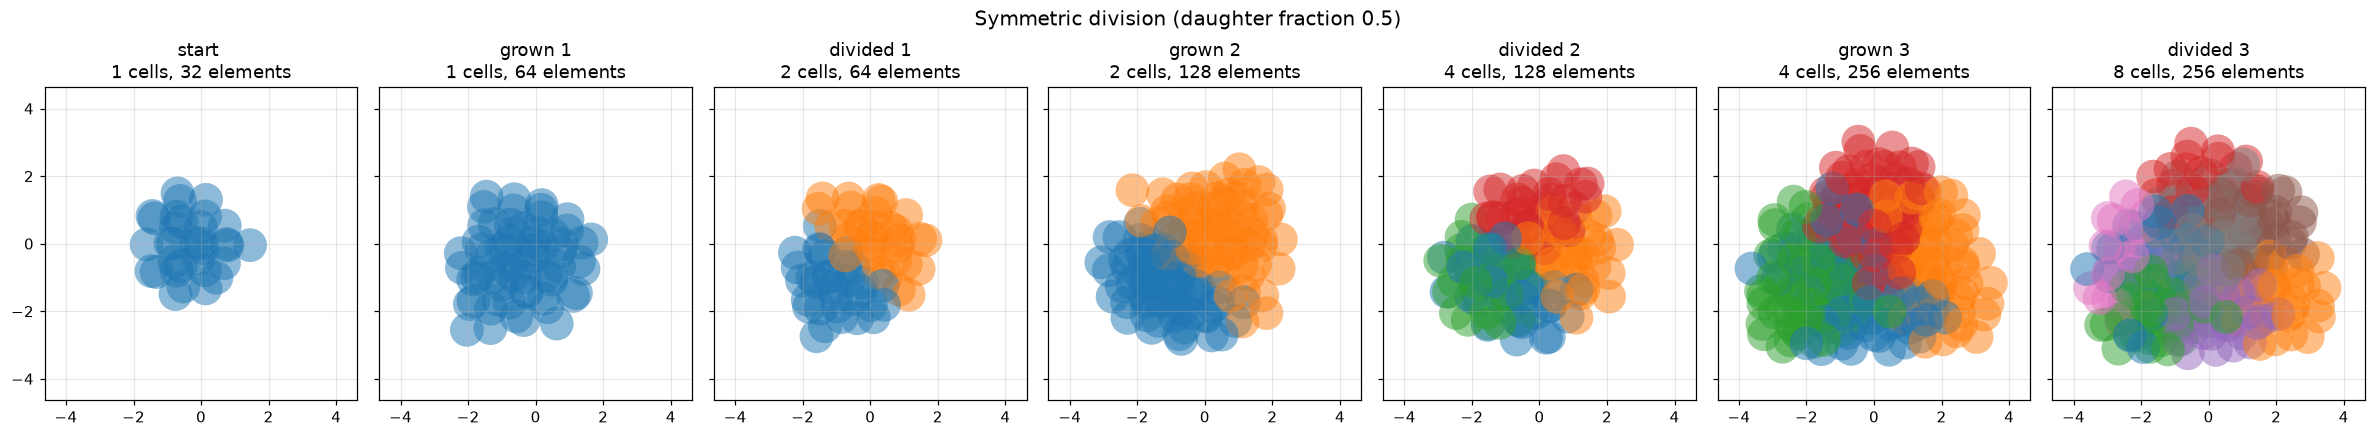

In [2]:
colors = plt.get_cmap("tab10")


def draw_run(snapshots, title):
    fig, axes = plt.subplots(1, len(snapshots), figsize=(3.1 * len(snapshots), 3.6), sharex=True, sharey=True)
    extent = max(np.abs(s["position"][:, :2]).max() for s in snapshots) + 1.0
    for ax, snapshot in zip(axes, snapshots):
        for (x, y), cell in zip(snapshot["position"][:, :2], snapshot["cell"]):
            ax.add_patch(plt.Circle((x, y), 0.5, color=colors(cell % 10), alpha=0.5, linewidth=0))
        ax.set(xlim=(-extent, extent), ylim=(-extent, extent), aspect="equal",
               title=f"{snapshot['phase']} {snapshot['generation'] or ''}\n{np.unique(snapshot['cell']).size} cells, {snapshot['cell'].size} elements")
    fig.tight_layout()
    fig.suptitle(title, y=1.08, fontsize=13)


draw_run(runs["0.5"], "Symmetric division (daughter fraction 0.5)")

## Asymmetric division

The same sequence with a daughter fraction of 0.3. Every division gives a small and a large daughter. Since
each cell then doubles its own size before dividing again, the population becomes a mixture of sizes.

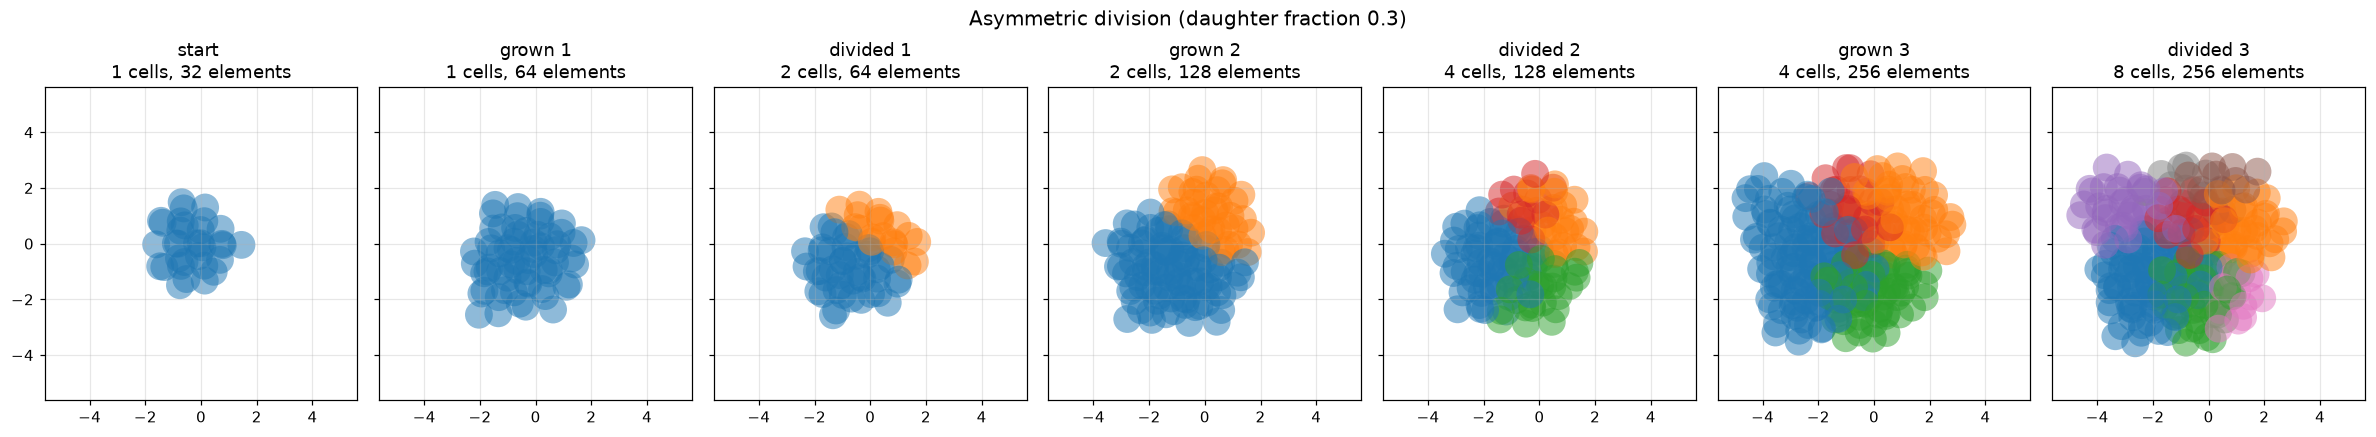

In [3]:
draw_run(runs["0.3"], "Asymmetric division (daughter fraction 0.3)")

## Cell sizes after three generations

fraction 0.5: 8 cells, sizes [32, 32, 32, 32, 32, 32, 32, 32], total 256
fraction 0.3: 8 cells, sizes [88, 38, 38, 38, 16, 16, 15, 7], total 256


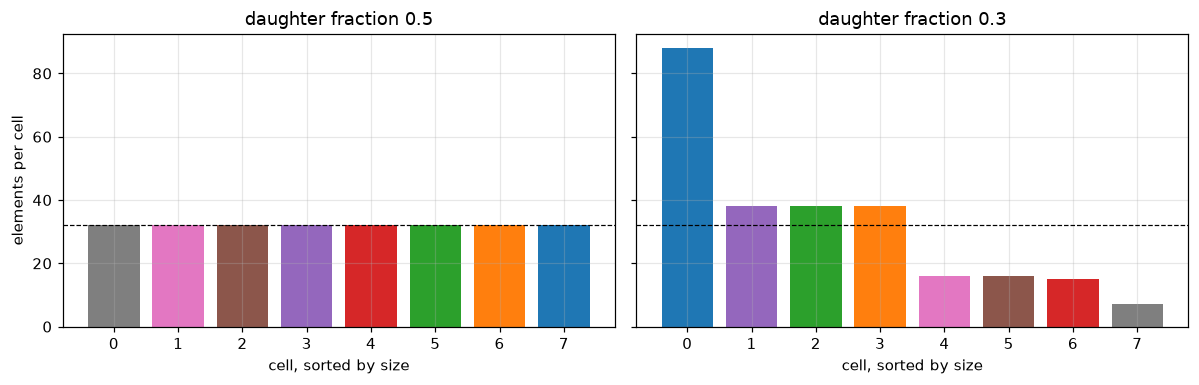

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
sizes = {}
for ax, fraction in zip(axes, ("0.5", "0.3")):
    final = runs[fraction][-1]
    cells_present, counts = np.unique(final["cell"], return_counts=True)
    sizes[fraction] = counts
    ax.bar(np.arange(counts.size), np.sort(counts)[::-1], color=[colors(c % 10) for c in cells_present[np.argsort(counts)[::-1]]])
    ax.axhline(32, color="black", linestyle="--", linewidth=0.8)
    ax.set(xlabel="cell, sorted by size", title=f"daughter fraction {fraction}")
axes[0].set_ylabel("elements per cell")
fig.tight_layout()

for fraction, counts in sizes.items():
    print(f"fraction {fraction}: {counts.size} cells, sizes {sorted(counts.tolist(), reverse=True)}, total {counts.sum()}")

In [5]:
# What must hold exactly
for fraction, snapshots in runs.items():
    for snapshot in snapshots:
        generation = snapshot["generation"]
        expected_elements = 32 * 2**generation
        expected_cells = 2**generation if snapshot["phase"] == "divided" else 2 ** max(generation - 1, 0)
        assert snapshot["cell"].size == expected_elements, (fraction, snapshot["phase"], generation)
        assert np.unique(snapshot["cell"]).size == expected_cells, (fraction, snapshot["phase"], generation)

assert set(sizes["0.5"]) == {32}, "symmetric division must give equal cells"
assert sizes["0.3"].min() < 32 < sizes["0.3"].max(), "asymmetric division must give unequal cells"

# In the first asymmetric division the daughter takes round(0.3 * 64) elements
first_division = runs["0.3"][2]
assert sorted(np.unique(first_division["cell"], return_counts=True)[1].tolist()) == [19, 45]

print("Element and cell counts are as expected in every snapshot.")

Element and cell counts are as expected in every snapshot.


## Reading the result

- **Counts are exact.** Elements double in every growth phase and cells double in every division. With a
  daughter fraction of 0.5 all eight cells hold 32 elements; with 0.3 the first division gives 19 and 45, and
  after three generations the cells range from small to large.
- **Daughters stay separate cells.** The colours do not mix: after a division each daughter rounds up, held
  together by the deeper intra-cellular well, and stays attached to its sister through the shallower one.
- **Division needs no extra force.** Nothing pushes the daughters apart; the change of potential across the
  plane is enough.

### What this does not show

- **No timing.** Growth here is "one element per cell every 0.05 time units" and division happens when the
  count has doubled. A growth rate or a cell cycle is the caller's business.
- **New elements attach at the surface.** In a packed cell there is no gap as wide as an element, so the
  position with the most room is normally on the outside. With the default potential the cell rearranges and
  stays compact; with a stiff potential ($\rho = 4$) and no noise it grows lumpy (see the solver tests).
- **No noise.** Thermal noise would let cells rearrange and would roughen the interfaces between them.
- **The direction of an asymmetric division** is the longest axis here, whose sign is a convention. To make
  the small daughter appear on a chosen side, pass a direction with a meaning, such as the motility direction.